Loaded 31 raga id mappings (30 unique raga labels)
Found 300 audio files with a known raga label under /kaggle/input/datasets/mishbhaul/indian-raga-dataset/RagaDataset/Hindustani/audio


Extracting features:   0%|          | 0/300 [00:00<?, ?it/s]

Note: Illegal Audio-MPEG-Header 0x00000000 at offset 2871.
Note: Trying to resync...
Note: Hit end of (available) data during resync.


FAILED  /kaggle/input/datasets/mishbhaul/indian-raga-dataset/RagaDataset/Hindustani/audio/063ea5a0-23b1-4bb5-8537-3d924fe8ebb3/Amir_Khan/From_The_Archives_Of_Sangeet_Natak_Akademi/Raga_Jog_7a383e3f-b0a6-4aca-92df-e53c3d928a2d.mp3: 

Saved 299 feature rows to features_60.csv
Ragas represented: 30 / 30 in the mapping
Total clips: 299
Unique ragas: 30
Unique artists: 56


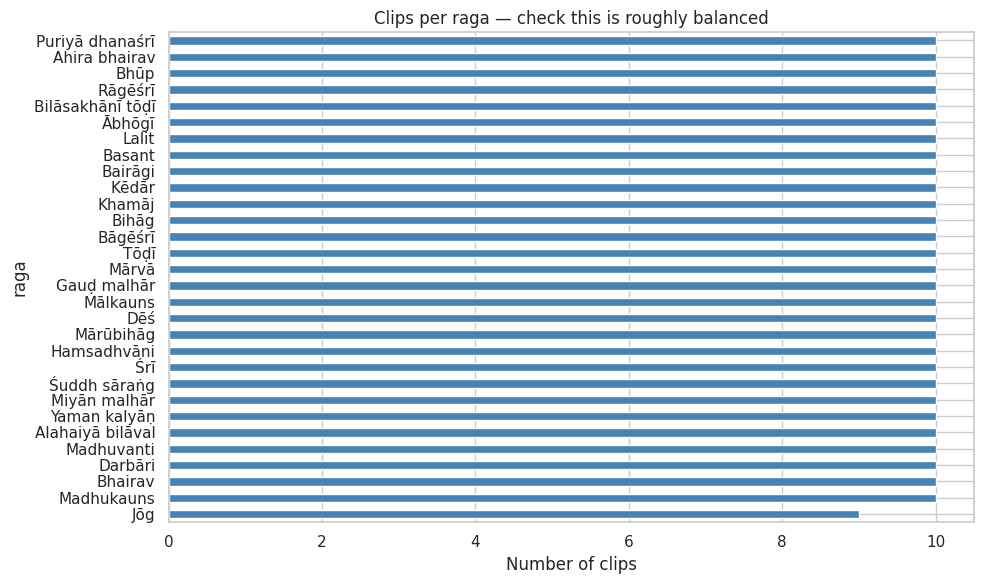

Ragas with only 1 artist in the dataset (leakage risk):
Series([], Name: artist, dtype: int64)


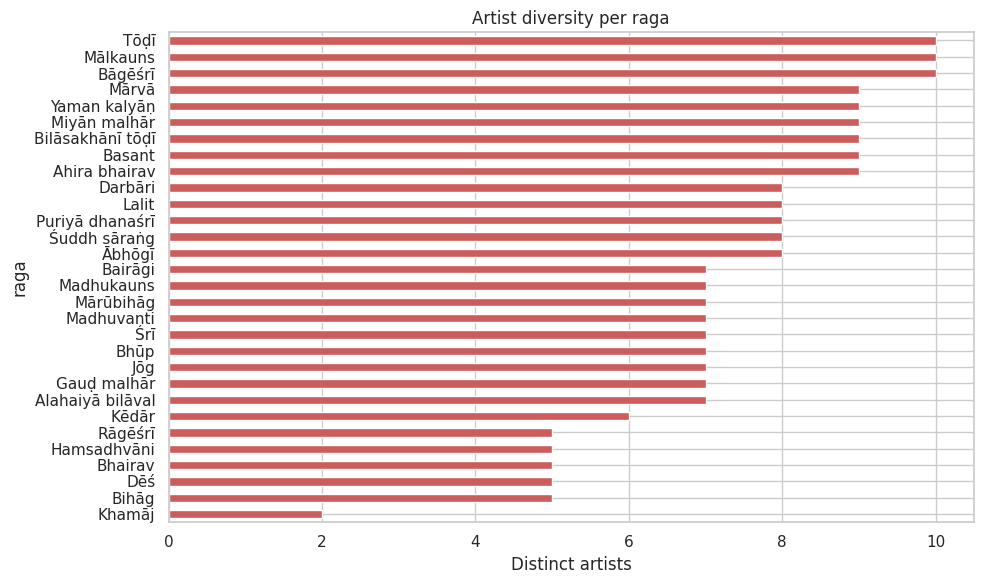

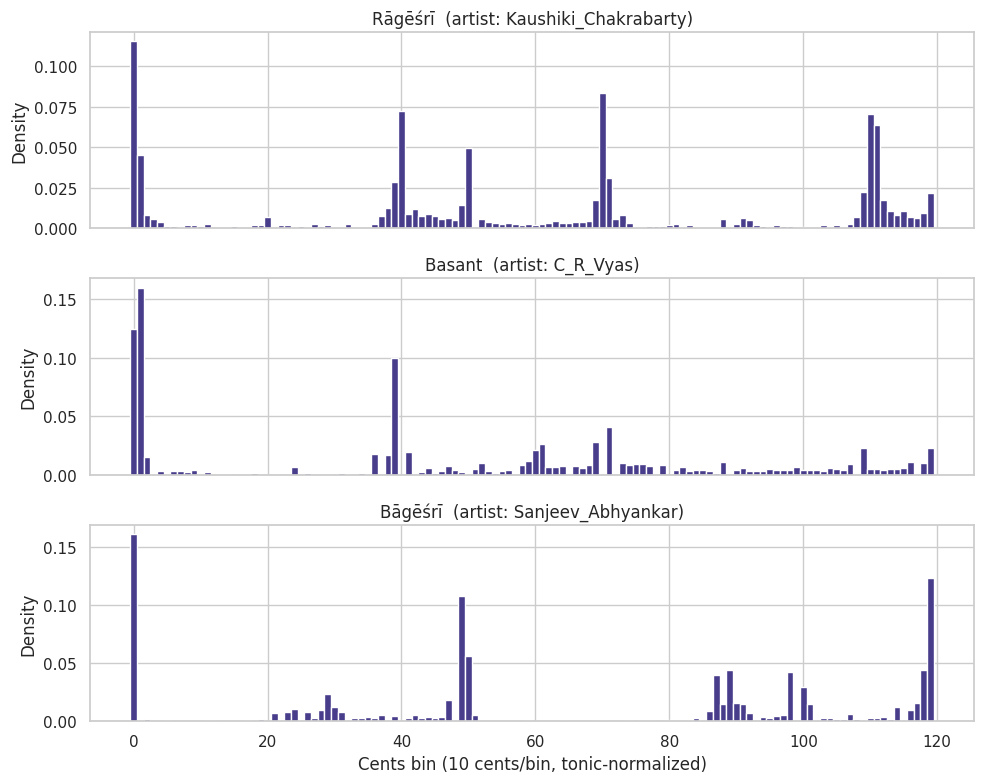

Evaluating PCD-only (primary feature set)...
Evaluating PCD + MFCC (ablation)...


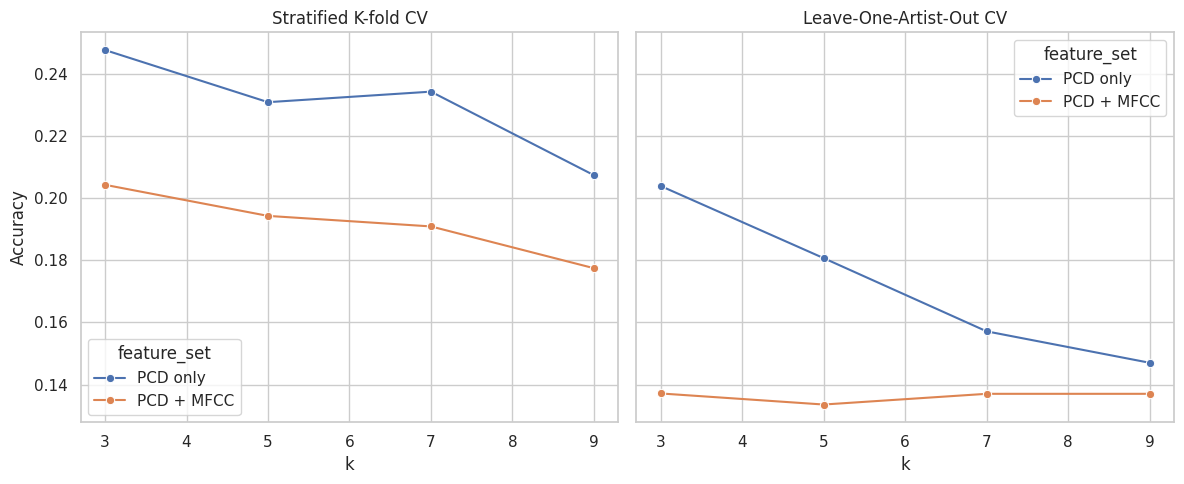

Best PCD-only:     k=3  stratified=0.248  leave-artist-out=0.204
Best PCD+MFCC:     k=3  stratified=0.204  leave-artist-out=0.137

MFCC lift on stratified CV:        -0.043
MFCC lift on leave-artist-out CV:  -0.067

✅ MFCC lift is consistent across both CV strategies — reasonably safe to keep MFCCs.


In [1]:
#!/usr/bin/env python
# coding: utf-8

# 
# # 🎼 Hindustani Raga Classification
# 
# **Task:** classify the raga of a Hindustani classical audio clip using
# melodic (pitch-based) features, with a timbral (MFCC) feature block kept
# separate for an explicit ablation study.
# 
# **Why this feature/model combo:**
# - Raga identity lives in *which notes are used, how often, and relative
#   to which tonic* — not in absolute pitch or timbre. So the primary
#   feature is a **tonic-normalized, high-resolution Pitch Class
#   Distribution (PCD)** — think of it as a fine-grained, tonic-relative
#   chroma (10-cent bins instead of 12 semitones, to capture microtonal
#   ornamentation / gamakas).
# - MFCCs capture *timbre* (voice/instrument texture), which is more tied
#   to the **performer** than the raga. With only 10 songs/raga, and folders
#   organized as `Artist -> Raga`, there's real risk of the model learning
#   "this sounds like Ajoy Chakraborty" instead of "this is Raag Kedar."
#   So MFCCs are tested as an **optional add-on**, and we explicitly check
#   whether they help *only* on a naive split (red flag) or also on a
#   **leave-one-artist-out** split (real signal).
# - **k-Nearest Neighbors (KNN)** is a sensible baseline here: with ~300
#   clips total, there isn't enough data to justify a deep model, and KNN
#   on a well-designed feature vector is a strong, interpretable baseline
#   in raga-recognition literature.
# 
# **Notebook structure** (each section is a self-contained, reusable
# function — run top to bottom, or import into your own scripts):
# 
# 1. Config
# 2. Raga UUID → label mapping
# 3. File discovery (UUID-based, Kaggle-duplicate-safe)
# 4. Feature extraction: tonic estimation, PCD, MFCC
# 5. Build the feature table (the only slow step — cached to CSV)
# 6. EDA — sanity-check the dataset before modeling
# 7. Modeling — KNN + Stratified CV + Leave-One-Artist-Out CV
# 8. MFCC ablation study & verdict
# 

# 
# ## 1. Config
# 
# All tunable knobs live here — nowhere else in the notebook. Change the
# paths and re-run.
# 

# In[ ]:


from dataclasses import dataclass

@dataclass(frozen=True)
class Config:
    # --- paths -----------------------------------------------------
    audio_root: str = "/kaggle/input/datasets/mishbhaul/indian-raga-dataset/RagaDataset/Hindustani/audio"  # folder containing <uuid> subfolders
    features_csv: str = "features_60.csv"                          # cache for extracted features

    # --- audio -------------------------------------------------------
    sample_rate: int = 22050
    # ONLY first 3 minutes per clip to keep memory low and runtime sane
    analysis_duration: float | None = 90.0
    fmin_hz: float = 80.0                    # vocal/instrument pitch search range
    fmax_hz: float = 800.0
    cents_per_bin: int = 10                  # PCD resolution: 10 cents -> 120 bins/octave

    # --- modeling ------------------------------------------------------
    knn_k_values: tuple = (3, 5, 7, 9)
    random_seed: int = 42

CFG = Config()


# ## 2. Imports

# In[ ]:
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
np.random.seed(CFG.random_seed)


# 
# ## 3. Raga UUID → label mapping
# 
# Each raga's audio lives in its own UUID-named folder. This dict is the
# ground truth for labels — everything downstream is keyed off it.
# 

# In[ ]:
# Raga IDs for 300 Hindustani Classical Music clips (30 ragas x 10 songs)
ID_TO_RAGA = {
    'f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8 2': 'Rāgēśrī',
    'f6432fec-e9c2-4b09-9e73-c46086cbd8ea': 'Ahira bhairav',
    '290674e0-d94c-41c1-ad99-f65fa22a1447': 'Madhuvanti',
    '0b3bbf97-0ec3-41da-add4-722d87329ec3': 'Madhukauns',
    'a9ee554f-f146-43e9-b2d0-9bb31fd4b57d': 'Kēdār',
    'd9c603fa-875f-4b84-b851-c6a345427898': 'Ābhōgī',
    '1e7de02f-e77f-405a-a033-f31117aaf955': 'Bhairav',
    '3eb7ba30-4b94-432e-9618-875ee57e01ab': 'Mārvā',
    '46997b02-f09c-4969-8138-4e1861f61967': 'Śrī',
    '54c4214c-05b9-4acc-8f77-6d5786e43a2e': 'Mārūbihāg',
    'a99e07d5-20a0-467b-8dcd-aa5a095177fd': 'Lalit',
    '62b79291-73b0-4c77-a353-0f8bc6ed8362': 'Dēś',
    '118401e7-8de8-4d81-9d8e-8070889e3fa8': 'Darbāri',
    '7591faad-e68a-4550-b675-8082842c6056': 'Bāgēśrī',
    '93c73081-bdf8-4eca-b325-d736b71e9b4b': 'Khamāj',
    'ba3242d0-8d40-4d93-865e-d2e2497ea2a8': 'Gauḍ malhār',
    'ecd04ceb-b46c-47fc-9045-84ac9160e527': 'Basant',
    '6f13484e-6fdd-402d-baf3-3835835454d0': 'Tōḍī',
    'fa28470c-d413-44c7-94da-181f530cbfdd': 'Puriyā dhanaśrī',
    'f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8': 'Rāgēśrī',
    '40dbe1db-858f-4366-bef8-9076eb67340d': 'Śuddh sāraṅg',
    '1b05a564-059f-445b-b325-cf26318367e3': 'Miyān malhār',
    'b143adaa-f1a6-4de4-8985-a5bd35e96279': 'Bairāgi',
    '64e5fb9e-5569-4e80-8e6c-f543af9469c7': 'Mālkauns',
    '2ed9379f-14c9-49af-8e4d-f9b63e96801f': 'Alahaiyā bilāval',
    'e771a74d-545d-41d5-816b-43403a818b0c': 'Bhūp',
    '063ea5a0-23b1-4bb5-8537-3d924fe8ebb3': 'Jōg',
    'a7d98897-e2fe-4d75-b9dc-e5b4dc88e1c6': 'Bihāg',
    '48b37bed-e847-4882-8a01-5c721e07f07d': 'Yaman kalyāṇ',
    '595de771-fcc2-414c-9df6-ae4ffd898549': 'Hamsadhvāni',
    'dd59147d-8775-44ff-a36b-0d9f15b31319': 'Bilāsakhānī tōḍī',
}

print(f"Loaded {len(ID_TO_RAGA)} raga id mappings "
      f"({len(set(ID_TO_RAGA.values()))} unique raga labels)")


# 
# ## 4. File discovery
# 
# Each `<uuid>` folder under `audio_root` corresponds to one raga.
# Kaggle sometimes appends a duplicate suffix to a folder name
# (`... 2`, `... (2)`) when a dataset is re-uploaded — `clean_uuid`
# normalizes those away so they still resolve to the correct label.
# 
# Artist is inferred from the first sub-folder under each UUID folder
# (e.g. `<uuid>/Ajoy_Chakraborty/...`); it's used later for
# leave-one-artist-out cross-validation.
# 

# In[ ]:
AUDIO_EXTENSIONS = (".wav", ".mp3", ".flac", ".m4a")


def clean_uuid(raw_name: str) -> str:
    '''Normalize a folder name to its canonical uuid string.

    Strips whitespace and Kaggle-style duplicate suffixes such as
    ' 2' or ' (2)', and lowercases, so re-uploaded duplicate folders
    still map to the same raga.
    '''
    name = raw_name.strip()
    name = re.sub(r"\s*\(\d+\)$", "", name)   # trailing " (1)", " (2)"
    name = re.sub(r"\s+\d+$", "", name)       # trailing " 2", " 3"
    return name.lower()


def build_normalized_lookup(id_to_raga: dict) -> dict:
    '''Collapse duplicate-suffixed uuid keys into one clean lookup table.'''
    return {clean_uuid(k): v for k, v in id_to_raga.items()}


def find_audio_files_with_labels(root_dir: str, id_to_raga: dict) -> list[tuple[str, str, str]]:
    '''Walk `root_dir` and return (filepath, raga_label, artist) for every
    audio file whose parent uuid folder is present in `id_to_raga`.

    Folders not found in the mapping are skipped with a warning rather
    than silently dropped, so missing labels are easy to spot.
    '''
    lookup = build_normalized_lookup(id_to_raga)
    items = []

    for uuid_folder in sorted(os.listdir(root_dir)):
        uuid_path = os.path.join(root_dir, uuid_folder)
        if not os.path.isdir(uuid_path):
            continue

        raga_label = lookup.get(clean_uuid(uuid_folder))
        if raga_label is None:
            print(f"WARNING: no raga mapping for uuid folder '{uuid_folder}', skipping")
            continue

        for dirpath, _, filenames in os.walk(uuid_path):
            rel_path = os.path.relpath(dirpath, uuid_path)
            artist = rel_path.split(os.sep)[0] if rel_path != "." else "unknown"

            for fname in filenames:
                if fname.lower().endswith(AUDIO_EXTENSIONS):
                    items.append((os.path.join(dirpath, fname), raga_label, artist))

    return items


# 
# ## 5. Feature extraction
# 
# ### 5a. Tonic estimation
# 
# Hindustani music is *relative*-pitch based — "Sa" isn't a fixed
# frequency, it's whatever the performer sets. Every melodic feature below
# is meaningless unless it's normalized to the tonic first.
# 
# Approach: extract a pitch contour (pYIN), fold every voiced pitch into a
# single-octave cents histogram, and take the strongest peak as the tonic.
# This is a solid, dependency-light stand-in for Essentia's
# `TonicIndianArtMusic` — swap that in if you have Essentia installed, for
# likely better accuracy.
# 

# In[ ]:
def estimate_tonic(y: np.ndarray, sr: int, fmin: float = CFG.fmin_hz, fmax: float = CFG.fmax_hz) -> float:
    '''Estimate the tonic (Sa) frequency in Hz via pitch-histogram peak-picking.'''
    f0, voiced_flag, _ = librosa.pyin(y, fmin=fmin, fmax=fmax, sr=sr, frame_length=2048)

    voiced_f0 = f0[voiced_flag == True] if voiced_flag is not None else f0[~np.isnan(f0)]
    voiced_f0 = voiced_f0[~np.isnan(voiced_f0)]
    if len(voiced_f0) == 0:
        return 220.0  # fallback if the clip has no detectable pitch

    cents = 1200 * np.log2(voiced_f0 / fmin)
    cents_folded = np.mod(cents, 1200)

    hist, bin_edges = np.histogram(cents_folded, bins=120, range=(0, 1200))
    peak_cents = bin_edges[np.argmax(hist)]
    return float(fmin * (2 ** (peak_cents / 1200)))


# 
# ### 5b. Tonic-normalized Pitch Class Distribution (PCD) — primary feature
# 
# This is the melodic fingerprint of the raga: for every voiced frame,
# compute its distance from the tonic in cents, fold to one octave, and
# bin at high resolution. Ragas differ in *which* bins are populated
# (which swaras are used), how much weight each carries (vadi/samvadi),
# and the microtonal shape around each peak (gamakas) — all of which this
# captures.
# 

# In[ ]:
def extract_pitch_contour(y: np.ndarray, sr: int, fmin: float = CFG.fmin_hz, fmax: float = 1000.0):
    '''Extract a monophonic predominant-pitch contour via pYIN.'''
    f0, voiced_flag, _ = librosa.pyin(y, fmin=fmin, fmax=fmax, sr=sr, frame_length=2048)
    return f0, voiced_flag


def compute_pcd(f0: np.ndarray, voiced_flag: np.ndarray, tonic_hz: float,
                 cents_per_bin: int = CFG.cents_per_bin) -> np.ndarray:
    '''Fold voiced pitches into a tonic-relative, high-resolution PCD.

    Returns a probability distribution over `1200 // cents_per_bin` bins
    covering one octave (normalized so clip length doesn't matter).
    '''
    n_bins = 1200 // cents_per_bin
    if f0 is None:
        return np.zeros(n_bins)

    voiced = f0[voiced_flag == True] if voiced_flag is not None else f0[~np.isnan(f0)]
    voiced = voiced[~np.isnan(voiced)]
    voiced = voiced[voiced > 0]
    if len(voiced) == 0:
        return np.zeros(n_bins)

    cents_rel = 1200 * np.log2(voiced / tonic_hz)
    cents_folded = np.mod(cents_rel, 1200)

    hist, _ = np.histogram(cents_folded, bins=n_bins, range=(0, 1200))
    hist = hist.astype(float)
    return hist / hist.sum() if hist.sum() > 0 else hist


# 
# ### 5c. MFCC statistics — secondary / ablation-only feature
# 
# Captures timbre, not melody. Kept separate on purpose: we want to be
# able to train *with* and *without* this block to check whether it's
# teaching the model raga structure, or just performer identity.
# 

# In[ ]:
def extract_mfcc_stats(y: np.ndarray, sr: int, n_mfcc: int = 13) -> np.ndarray:
    '''Mean/std of MFCCs and their deltas, flattened to one feature vector.'''
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
    delta = librosa.feature.delta(mfcc)
    return np.concatenate([
        mfcc.mean(axis=1), mfcc.std(axis=1),
        delta.mean(axis=1), delta.std(axis=1),
    ])


# 
# ## 6. Build the feature table
# 
# The only slow step (pitch tracking dominates runtime). Results are
# cached to `CFG.features_csv` so you only pay this cost once — re-running
# the notebook loads the cache instead of re-extracting.
# 

# In[ ]:
def process_file(filepath: str, raga_label: str, artist: str,
                  sr_target: int = CFG.sample_rate,
                  duration: float | None = CFG.analysis_duration) -> dict:
    '''Load one clip and compute its full feature row.'''
    y, sr = librosa.load(filepath, sr=sr_target, duration=duration, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)

    tonic_hz = estimate_tonic(y, sr)
    f0, voiced_flag = extract_pitch_contour(y, sr)
    pcd = compute_pcd(f0, voiced_flag, tonic_hz)
    mfcc_stats = extract_mfcc_stats(y, sr)

    row = {"filepath": filepath, "artist": artist, "raga": raga_label, "tonic_hz": tonic_hz}
    row.update({f"pcd_{i}": v for i, v in enumerate(pcd)})
    row.update({f"mfcc_{i}": v for i, v in enumerate(mfcc_stats)})
    return row


def build_feature_table(root: str, id_to_raga: dict, out_csv: str) -> pd.DataFrame:
    '''Extract features for every labeled audio file and cache to CSV.
    
    Sequential loop — no joblib / no parallelism to avoid segfaults.
    '''
    labeled_files = find_audio_files_with_labels(root, id_to_raga)
    print(f"Found {len(labeled_files)} audio files with a known raga label under {root}")

    rows = []
    for filepath, raga_label, artist in tqdm(labeled_files, desc="Extracting features"):
        try:
            rows.append(process_file(filepath, raga_label, artist))
        except Exception as e:
            print(f"FAILED  {filepath}: {e}")

    df = pd.DataFrame(rows)
    df.to_csv(out_csv, index=False)

    n_ragas = df["raga"].nunique() if len(df) else 0
    print(f"\nSaved {len(df)} feature rows to {out_csv}")
    print(f"Ragas represented: {n_ragas} / {len(set(id_to_raga.values()))} in the mapping")
    return df


# In[ ]:
# Extract once, cache forever. Delete the CSV (or change CFG.features_csv) to force a re-run.
if os.path.exists(CFG.features_csv):
    print(f"Loading cached features from {CFG.features_csv}")
    features_df = pd.read_csv(CFG.features_csv)
else:
    features_df = build_feature_table(CFG.audio_root, ID_TO_RAGA, CFG.features_csv)

features_df.head()


# 
# ## 7. Exploratory data analysis
# 
# Quick sanity checks before modeling — always look at your data first.
# 

# In[ ]:
print(f"Total clips: {len(features_df)}")
print(f"Unique ragas: {features_df['raga'].nunique()}")
print(f"Unique artists: {features_df['artist'].nunique()}")

fig, ax = plt.subplots(figsize=(10, 6))
features_df["raga"].value_counts().sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Number of clips")
ax.set_title("Clips per raga — check this is roughly balanced")
plt.tight_layout()
plt.show()


# In[ ]:
# How many artists sing each raga? A raga with only ONE artist is a
# leakage risk: the model could learn "that voice" instead of the raga.
artist_coverage = features_df.groupby("raga")["artist"].nunique().sort_values()
print("Ragas with only 1 artist in the dataset (leakage risk):")
print(artist_coverage[artist_coverage == 1])

fig, ax = plt.subplots(figsize=(10, 6))
artist_coverage.plot(kind="barh", ax=ax, color="indianred")
ax.set_xlabel("Distinct artists")
ax.set_title("Artist diversity per raga")
plt.tight_layout()
plt.show()


# In[ ]:
# Sanity-check the PCD shape: plot a few example distributions.
pcd_cols = [c for c in features_df.columns if c.startswith("pcd_")]

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, (_, row) in zip(axes, features_df.sample(3, random_state=CFG.random_seed).iterrows()):
    ax.bar(range(len(pcd_cols)), row[pcd_cols].values, width=1.0, color="darkslateblue")
    ax.set_title(f"{row['raga']}  (artist: {row['artist']})")
    ax.set_ylabel("Density")
axes[-1].set_xlabel("Cents bin (10 cents/bin, tonic-normalized)")
plt.tight_layout()
plt.show()


# 
# ## 8. Modeling — KNN with two feature sets, two CV strategies
# 
# Two things are being tested at once:
# 
# | | **PCD only** | **PCD + MFCC** |
# |---|---|---|
# | **Stratified K-fold** | baseline accuracy | does adding MFCC help? |
# | **Leave-one-artist-out** | true raga-generalization accuracy | does the MFCC "help" survive when artists don't overlap between train/test? |
# 
# If PCD+MFCC beats PCD-only on stratified CV but **not** on
# leave-one-artist-out CV, that's the signature of artist leakage — the
# model was cheating by learning voices, not ragas.
# 

# In[ ]:
def evaluate_feature_set(X: np.ndarray, y: np.ndarray, groups: np.ndarray,
                          k_values=CFG.knn_k_values) -> pd.DataFrame:
    '''Run KNN over a grid of k, under both stratified and group (leave-one-artist-out) CV.'''
    results = []
    for k in k_values:
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("knn", KNeighborsClassifier(n_neighbors=k)),
        ])

        n_splits_strat = max(2, min(5, pd.Series(y).value_counts().min()))
        skf = StratifiedKFold(n_splits=n_splits_strat, shuffle=True, random_state=CFG.random_seed)
        strat_scores = cross_val_score(pipe, X, y, cv=skf, scoring="accuracy")

        n_splits_group = min(len(set(groups)), 10)
        gkf = GroupKFold(n_splits=n_splits_group)
        group_scores = cross_val_score(pipe, X, y, cv=gkf, groups=groups, scoring="accuracy")

        results.append({
            "k": k,
            "stratified_acc_mean": strat_scores.mean(),
            "stratified_acc_std": strat_scores.std(),
            "leave_artist_out_acc_mean": group_scores.mean(),
            "leave_artist_out_acc_std": group_scores.std(),
        })
    return pd.DataFrame(results)


# In[ ]:
mfcc_cols = [c for c in features_df.columns if c.startswith("mfcc_")]
y = features_df["raga"].values
groups = features_df["artist"].values

print("Evaluating PCD-only (primary feature set)...")
results_pcd = evaluate_feature_set(features_df[pcd_cols].fillna(0.0).values, y, groups)
results_pcd.insert(0, "feature_set", "PCD only")

print("Evaluating PCD + MFCC (ablation)...")
results_pcd_mfcc = evaluate_feature_set(features_df[pcd_cols + mfcc_cols].fillna(0.0).values, y, groups)
results_pcd_mfcc.insert(0, "feature_set", "PCD + MFCC")

results_df = pd.concat([results_pcd, results_pcd_mfcc], ignore_index=True)
results_df


# ## 9. MFCC ablation — visual + verdict

# In[ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, metric, title in zip(
    axes,
    ["stratified_acc_mean", "leave_artist_out_acc_mean"],
    ["Stratified K-fold CV", "Leave-One-Artist-Out CV"],
):
    sns.lineplot(data=results_df, x="k", y=metric, hue="feature_set", marker="o", ax=ax)
    ax.set_title(title)
    ax.set_ylabel("Accuracy")
plt.tight_layout()
plt.show()


# In[ ]:
best_pcd = results_pcd.loc[results_pcd["leave_artist_out_acc_mean"].idxmax()]
best_pcd_mfcc = results_pcd_mfcc.loc[results_pcd_mfcc["leave_artist_out_acc_mean"].idxmax()]

strat_lift = best_pcd_mfcc["stratified_acc_mean"] - best_pcd["stratified_acc_mean"]
group_lift = best_pcd_mfcc["leave_artist_out_acc_mean"] - best_pcd["leave_artist_out_acc_mean"]

print(f"Best PCD-only:     k={int(best_pcd.k)}  stratified={best_pcd.stratified_acc_mean:.3f}  "
      f"leave-artist-out={best_pcd.leave_artist_out_acc_mean:.3f}")
print(f"Best PCD+MFCC:     k={int(best_pcd_mfcc.k)}  stratified={best_pcd_mfcc.stratified_acc_mean:.3f}  "
      f"leave-artist-out={best_pcd_mfcc.leave_artist_out_acc_mean:.3f}")
print(f"\nMFCC lift on stratified CV:        {strat_lift:+.3f}")
print(f"MFCC lift on leave-artist-out CV:  {group_lift:+.3f}")

if strat_lift > 0.05 and group_lift <= 0.01:
    print("\n⚠️  WARNING: MFCCs help a lot on stratified CV but not on leave-artist-out CV.")
    print("   This is the classic artist-leakage signature — the model is likely learning")
    print("   singer timbre, not raga structure. Prefer the PCD-only model.")
else:
    print("\n✅ MFCC lift is consistent across both CV strategies — reasonably safe to keep MFCCs.")


# 
# ## Next steps
# 
# - If leave-one-artist-out accuracy is much lower than stratified accuracy
#   (for PCD-only too), that's a sign the dataset's melodic variation
#   between performances of the same raga is large — consider adding
#   melodic *motif* features (n-grams of swara transitions) or the
#   Time-Delayed Melodic Surface (TDMS), which are more robust to
#   performer-specific phrasing than a flat PCD.
# - Try `k` values outside `CFG.knn_k_values`, or swap KNN for an SVM /
#   Random Forest on the same feature table — the feature extraction code
#   above doesn't change either way.     
#   `TonicIndianArtMusic` — purpose-built and validated for Indian art
#   music, likely more accurate than the histogram-peak approach here.